# Multi frame prediction and saving new annotations in COCO format

## Repository structure

- **00_bysp_img_msk_adjust.ipynb**  
  Preprocess images and masks per species

- **01_NI_create_custom_coco_dataset.ipynb**  
  Create COCO-style datasets per species

- **03_cell_instance_recognition.ipynb**  
  Train instance segmentation models per species

- **04_NI_single_frame_segmentation.ipynb**  
  Inference using trained checkpoints

- **05_no_clear_border.ipynb**  
  Analysis and visualisation of ambiguous cell boundaries



### Dataset directory layout

```text
dataset/
└─ {species}/
   └─ png_256/
      ├─ image/
      │  ├─ train/
      │  └─ test/
      └─ annotation/


In [1]:
import cv2
import numpy as np
from tqdm import tqdm
from PIL import Image
import matplotlib.pyplot as plt
import time
import itertools

from skimage import data, graph
from skimage.filters import threshold_otsu
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops, regionprops_table
from skimage.morphology import closing, square
from skimage.color import label2rgb

import numpy as np
import torch
import cv2
from skimage.segmentation import expand_labels

###### Semantic and mask segmentation Model : Mask-RCNN-FPN.v2
#### Model used is 256_Sapindaceae_222_epoch.tar : based on 256x256 data after 222 epoch

The large image is divided into patches, and instance cell segmentation was preformed from each patches. Next, results are unpatched and pasted together so that the boundary parts are not noticeable.
From the image obtained, (A) the predicted regional information is saved in coco-format, and (B) the region adjacency graph after region expansion is created and saved. (A) is used for modification or collection of predicted annotation with coco_anotator software (MIT), and (B) is used for preliminary analysis of the cell-cell network.

### Read prediction model

## Prediction

In [2]:
import os
import torch
from src.load_mrcnn import get_model, load_checkpoint, predict_multi_frame

''' set gpu to be used '''
GPU_ID = 0
DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-4


############################

image_size = 512  # choice is 256 or 512
IMAGE_SIZE = [image_size, image_size] 
sp = "alllit"
line_thick = "_thin" #leave it blank when usin ""

############################

# test image to read
TEST_DIR = f'dataset/{sp}/png_'+str(image_size)+'/image/test'

# load mrcnn model 
MODEL_FILE = f"{image_size}{line_thick}_{sp}_700_epoch.tar" ###################### change model
dir_inferresult= f"{image_size}{line_thick}_singlesp_700_epoch.tar"

base_dir = './inference_results_without_clearborder'
#sub_dir = os.path.join(base_dir, f'{image_size}_singlespecies_700_epoch') ##############Change here when using thin_dataset
sub_dir = os.path.join(base_dir, f'{image_size}{line_thick}_singlespecies_700_epoch') ##############Change here when using thin_dataset


# Image to be predict
#data_img = 'dataset/performance_check/img/burspi1_01_img.png'

sp_to_filename = {
    "acapod": "acapod2_01_img.png",
    "alllit": "alllit2_01_img.png",
    "burspi": "burspi1_01_img.png",
    "euclon": "euclon1_01_img.png",
    "exostr": "exostr8_01_img.png",
    "hakdac": "hakdac2_01_img.png"
}

filename = sp_to_filename[sp]
input_dir = 'dataset/performance_check/image'
data_img = os.path.join('dataset/performance_check/image', filename)

############################


model = get_model()
model.to(DEVICE)   
optimizer = torch.optim.AdamW(params=model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY
                                  )
load_checkpoint(torch.load(os.path.join('./model',MODEL_FILE),weights_only=True), model, optimizer, LEARNING_RATE)

model.eval()

print("GPU:{}".format(GPU_ID)+' will be used for calculation!')



=> Loading checkpoint
GPU:0 will be used for calculation!


In [3]:
model.train(False)

img_num = 1

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]
print('You have ', str(len(testfilename)-1), \
      ' test images, and you selected image No. ', str(img_num))
img0 = Image.open(os.path.join(TEST_DIR,testfilename[img_num])).convert('RGB')


You have  7  test images, and you selected image No.  1


Check model using test image !

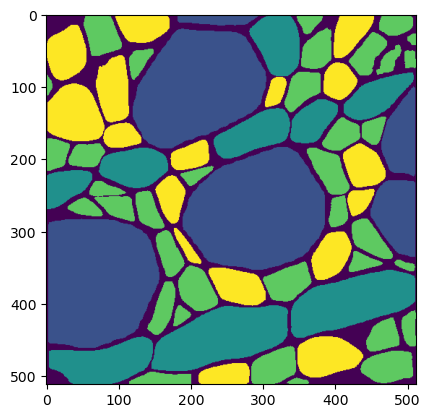

In [4]:
img = cv2.imread(os.path.join(TEST_DIR,testfilename[img_num]))
res2 = predict_multi_frame(model, img, IMAGE_SIZE, 0.7, 0.7, DEVICE)
plt.imshow(res2)
plt.show()

I decided to cut out a 320x320 central part of a 512x512 image and paste it together to recover original size.

First, an image with 96 pixels of padding in four directions was created, and for every 512x512 image cut out with a shift of 320 pixels, a label was predicted, and the central 320x320 of the predicted image was cut out and stored in an array of the same size as the empty original image.

sz: スライディングウィンドウの移動ステップ
pad: モデル入力に必要な余白サイズ（パッチサイズは sz + 2*pad）
l: range(N)：画像を sz ピクセルごとに N 回スライドさせるためのインデックスリスト

16it [00:02,  6.89it/s]


GPU time =  2.3237030506134033  sec


(-0.5, 1535.5, 1535.5, -0.5)

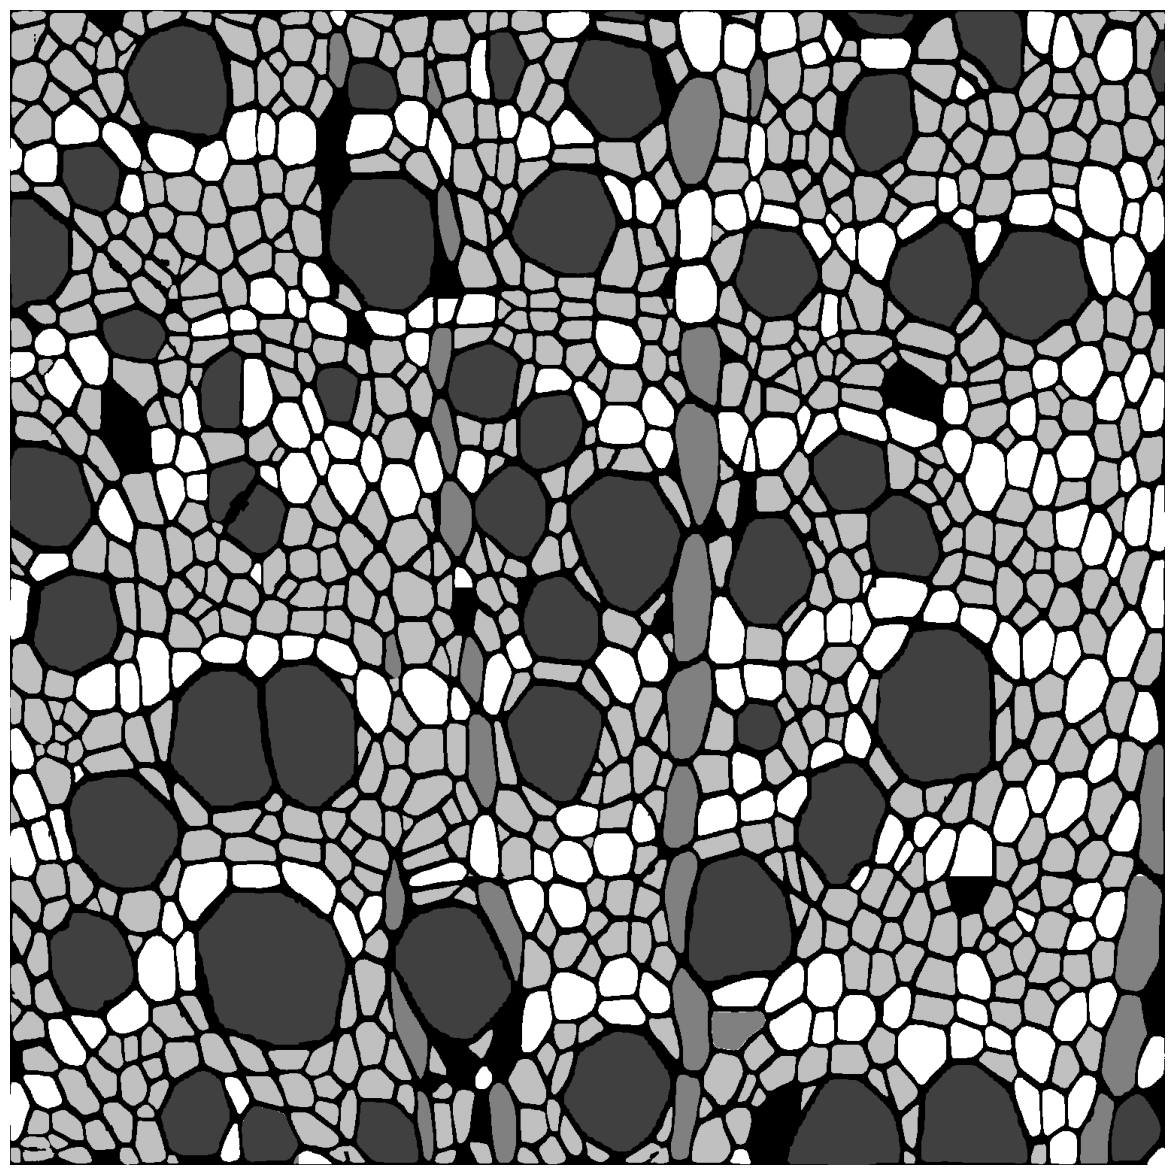

In [5]:
if image_size == 512:
    pad = 64
    sz = 384
    l = list(range(4))
elif image_size == 256:
    pad = 32
    sz = 192
    l = list(range(8))
else:
    raise ValueError(f"Unsupported image_size: {image_size}")


img_in = cv2.imread(data_img)
img_padded = cv2.copyMakeBorder(img_in, pad, pad, pad, pad, cv2.BORDER_CONSTANT, (0,0,0))
height, width, _ = img_padded.shape

img_pred = np.zeros_like(img_in[:,:,0])
start = time.time()


for i,j in tqdm(itertools.product(l, l)): 
    img_patch = img_padded[sz*i:sz*i+image_size, sz*j:sz*j+image_size, :]
    res2 = predict_multi_frame(model, img_patch, IMAGE_SIZE, 0.7, 0.9, DEVICE)  
    res2 = res2[pad:pad+sz,pad:pad+sz]
    img_pred[sz*i:sz*i+sz,sz*j:sz*j+sz]=res2
end = time.time()


fnam = os.path.splitext(os.path.basename(data_img))[0]
os.makedirs(sub_dir, exist_ok=True)

os.makedirs(os.path.join(sub_dir, 'prediction_raw'),exist_ok=True)

integ_img = Image.fromarray(img_pred)
integ_img.save(os.path.join(sub_dir, 'prediction_raw', fnam+'_prediction_raw.png'))

print( 'GPU time = ', end - start, ' sec')
fig = plt.subplots(figsize=(15,15))
plt.imshow(img_pred,cmap='gray')
plt.axis('off')


In [6]:
import numpy as np

unique_values = np.unique(img_pred)

print("img_pred に含まれるグレイレベルの値:", unique_values)
print("値の数:", len(unique_values))


img_pred に含まれるグレイレベルの値: [  0  64 128 192 255]
値の数: 5


In [7]:
print(img_pred.shape)


(1536, 1536)


## Relabelling whole image from patched predicted image

(1) Predicted labels are labelled with skimage. If the graph is created as it is, boundaries are all connected to each other, so they are extended with the expand_labels function until there are no boundaries (in fact, they do not disappear completely, so they are removed after the graph is created).

(2) Predicted labels on edges were removed by the clear_border function. cleared_labels contains zero values in the parts that could not be annotated, so node number zeros were removed after the graph was formed.


In [8]:
from skimage import data, graph
from skimage.filters import threshold_otsu
from skimage.segmentation import clear_border
from skimage.measure import label, regionprops, regionprops_table
from skimage.morphology import closing, square
from skimage.color import label2rgb
from skimage.measure import label
from skimage.segmentation import expand_labels, clear_border
import matplotlib.pyplot as plt
from PIL import Image
import os

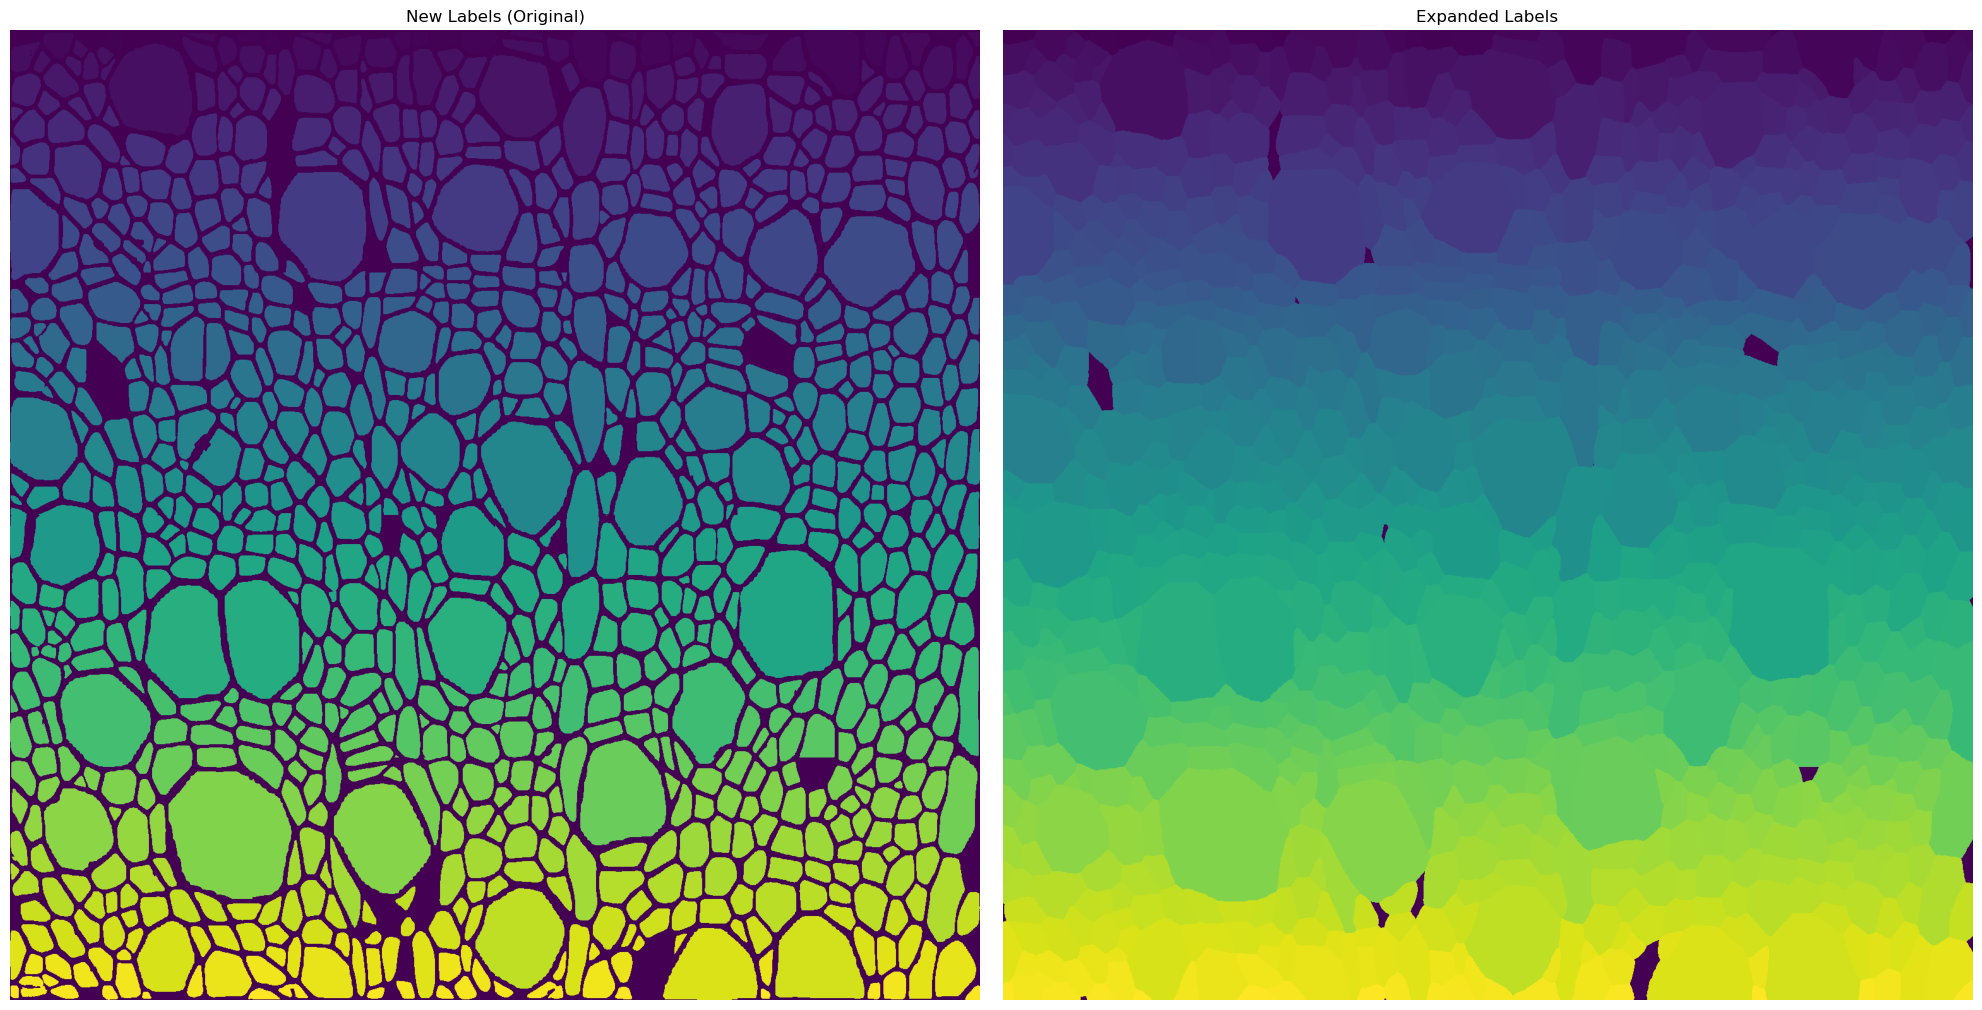

In [9]:

# ラベリング
new_labels = label(img_pred > 0)

# ラベル拡張
expanded_labels = expand_labels(new_labels, distance=15)
#cleared_labels_expanded = clear_border(expanded_labels)
#cleared_labels = clear_border(new_labels)

# 並列プロット
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

axes[0].imshow(new_labels)
axes[0].set_title("New Labels (Original)")
axes[0].axis("off")

axes[1].imshow(expanded_labels)
axes[1].set_title("Expanded Labels")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# 保存も継続（単体で）
#nil = Image.fromarray(new_labels)
#nil.save(os.path.join(sub_dir, fnam+'_new_label.png'))


# cleared labelも同様に
#cleared_png_path = os.path.join(sub_dir, f"{fnam}_cleare_border.png")
#cleared_npy_path = os.path.join(sub_dir, f"{fnam}_cleare_border.npy")

#Image.fromarray(cleared_labels.astype(np.uint16)).save(cleared_png_path)
#np.save(cleared_npy_path, cleared_labels)


In [10]:
#np.unique(cleared_labels)

In [11]:
# fig, ax = plt.subplots(figsize=(15,15))
# plt.imshow(cleared_labels)
# plt.show()

Predictive maps of cell types were labelled and the morphological elements were obtained from them using the reagionalprops function of SKIMAGE, and then stored in the panda data.

In [12]:
import pandas as pd

In [13]:
props = regionprops_table(
    new_labels,
    properties=('label','centroid','bbox', 'orientation', 'axis_major_length', 'axis_minor_length', 'area'),
)
df = pd.DataFrame(props)


Image processing in this area has been devised. The reason for this is to prevent misidentification of cell types due to the colour spreading outside the original image when the area is extended.
If there is a neighbouring area that is not well discriminated, it may be defeated by majority decision by the background colour.
In this case, the cells become the background, so if the background colour is chosen, the second colour is chosen for the cell type by majority vote.

In [14]:
def get_gray(p):
    output = img_pred[new_labels == p]
    out = output[np.isin(output, [64, 128, 192, 255])]
    if len(out) == 0:
        return 0  # fallback if region is empty
    gl = np.argmax(np.bincount(out))
    return gl
  # error appeared if .astype('int') is added.
    
t1 = time.time()  
label_list = np.unique(new_labels)[1:]
lbl1 = [*map(lambda x: get_gray(x),label_list)]
df['gray'] = lbl1
t2 = time.time()
print(str(t2-t1)+" sec")

0.8018479347229004 sec


In [15]:
# lbl1 == lbl2

Summary of colours and grey levels for cell types. A confusion matrix was also created for use in the graphs to determine the combined species.

link-table
|            | vessel | ray  | fiber | parenchyma |  
| ---------- | ------ | ---- | ----- | ---------- |
| vessel     | 1      | 2    | 3     | 2          |
| ray        | 2      | 4    | 6     | 4          |
| fiber      | 3      | 6    | 9     | 6          |
| parenchyma | 2      | 4    | 6     | 4          |



| cell_type | 'stuff' | 'vessel'             | 'ray'                     | 'fiber'                    | 'parenchyma'        |
| --------- | ------- | -------------------- | ------------------------- | -------------------------- | ------------------- |
| color     | (0,0,0) | （1,159/255,155/255) | (144/255,229/255,161/255) | (161/255,201/255,244/255), | (1,180/255,130/255) |
| gray      | 0       | 64                   | 128                       | 192                        | 255                 |

In [16]:
# definition of color graylevel celltype 
color = [(0,0,0),(1,159/255,155/255),(144/255,229/255,161/255),\
              (161/255,201/255,244/255),(1,180/255,130/255)]
cell_type = ['stuff','vessel','ray','fiber','parenchyma']
gray = [  0,  64, 128, 192, 255]

gr_cell_dict = dict(zip(gray,cell_type))
gr_c_dict = dict(zip(gray,color))
cell_gr_dict = dict(zip(cell_type,gray))
cell_c_dict = dict(zip(cell_type,color))

In [17]:
cell_types =[]
colors = []
for i in tqdm(range(len(df))):
    cell_types.append(gr_cell_dict[df['gray'].values[i]])
    colors.append(gr_c_dict[df['gray'].values[i]])
df['color'] = colors
df['anatomy'] = cell_types
#df.drop(0, axis=0)

100%|████████████████████████████████████████████████████████████████████| 983/983 [00:00<00:00, 186594.90it/s]


In [18]:
df

,label,centroid-0,centroid-1,bbox-0,bbox-1,bbox-2,bbox-3,orientation,axis_major_length,axis_minor_length,area,gray,color,anatomy
0,1,8.430645,23.366129,1,2,20,48,-1.472636,47.585476,17.192104,620.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber
1,2,10.105189,200.907433,1,182,25,228,-1.353248,48.316605,20.297975,713.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber
2,3,8.801917,436.619808,1,426,21,448,0.839379,21.610269,19.655455,313.0,255,"(1, 0.7058823529411765, 0.5098039215686274)",parenchyma
3,4,13.773784,686.380550,1,667,28,708,-1.532373,43.740518,27.923391,946.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber
4,5,7.237113,1481.560825,1,1461,16,1503,1.545557,42.699947,14.945504,485.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978,979,1525.470588,971.480392,1515,958,1535,985,1.456920,25.909505,21.248554,408.0,255,"(1, 0.7058823529411765, 0.5098039215686274)",parenchyma
979,980,1525.065617,579.383202,1516,565,1534,593,-1.252745,29.624794,16.697256,381.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber
980,981,1527.513072,399.544118,1517,377,1535,428,1.491797,48.355349,17.523119,612.0,255,"(1, 0.7058823529411765, 0.5098039215686274)",parenchyma
981,982,1526.377551,1195.260204,1518,1189,1534,1204,0.738865,18.288468,14.103284,196.0,192,"(0.6313725490196078, 0.788235294117647, 0.9568...",fiber


### Save all segmentation results in numpy archive

***

In [19]:
### Save new annotation in COCO format

Map anatomy data on the new labels.

In [20]:

import copy
#set function
new_labels_copy=copy.deepcopy(new_labels).flatten()
new_annotation=np.zeros((len(new_labels_copy)))

t1 = time.time()
replace_func = {label: new for new , label in zip(list(df['gray'].values), list(df['label'].values))}

#replace label values to anatomical values
replace_result=np.asarray(list(map(replace_func.get, new_labels_copy.flatten())))
result_index=np.where(replace_result!=None)[0]

#project the result to zero map
new_annotation[result_index]=replace_result[result_index]
t2 = time.time()
print(str(t2-t1)+" sec")

0.6987624168395996 sec


Check new labels 

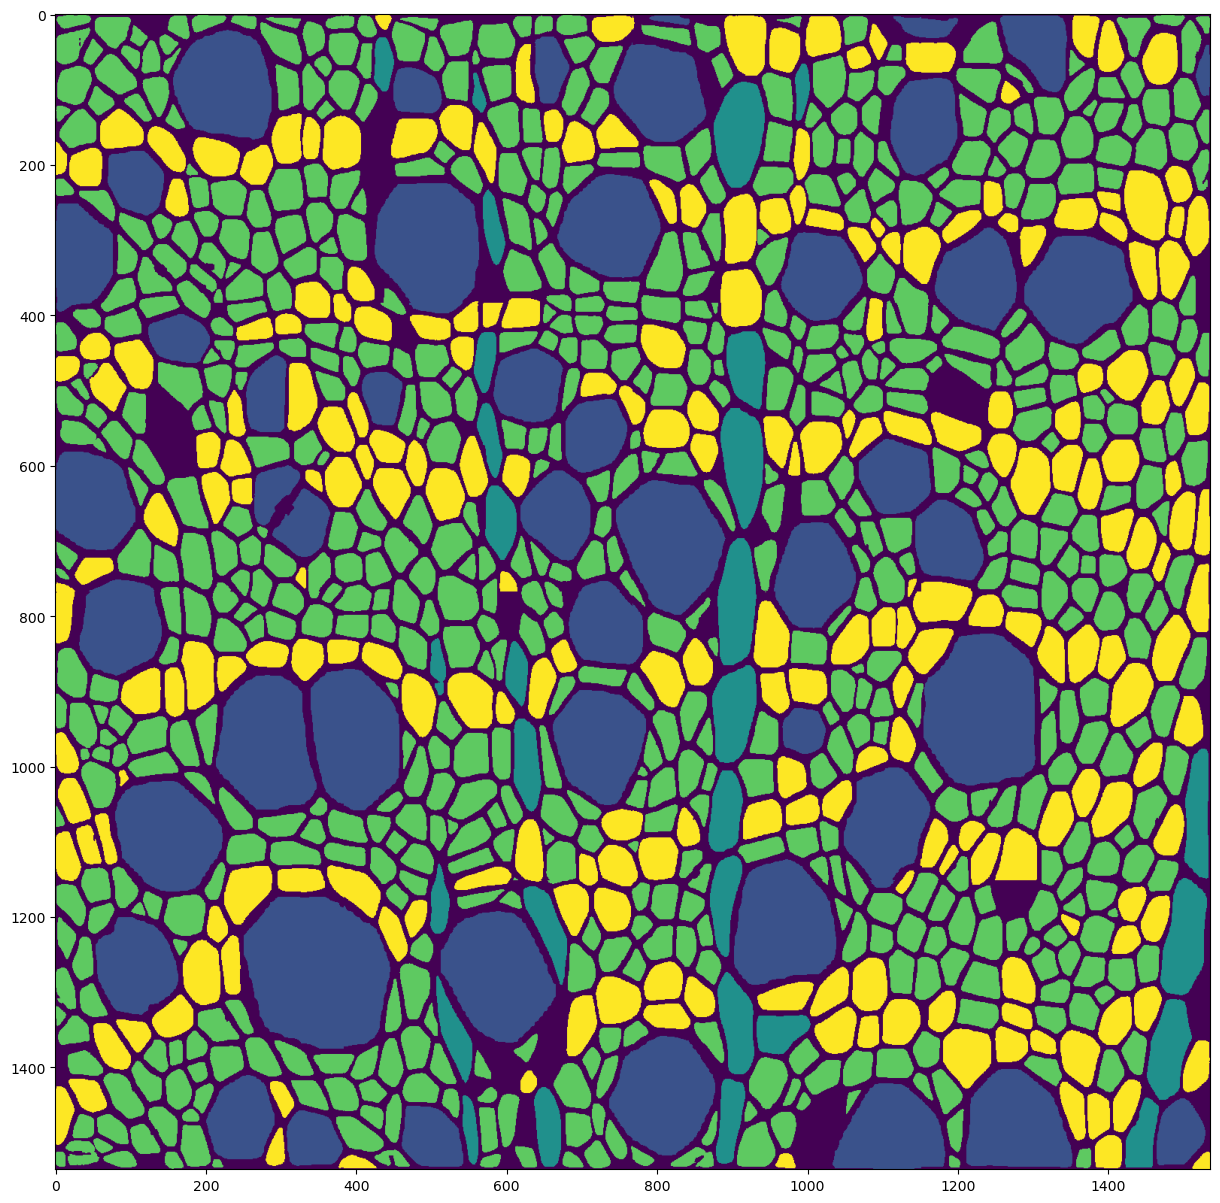

In [21]:
newly_annotated_img = new_annotation.reshape((new_labels.shape))

fig, ax = plt.subplots(figsize=(15,15))
ax.imshow(newly_annotated_img)
nai = Image.fromarray(newly_annotated_img.astype('uint8'))
os.makedirs(os.path.join(sub_dir, 'prediction_cleaned'), exist_ok=True)
nai.save(os.path.join(sub_dir, 'prediction_cleaned',fnam+'_pred_cleaned.png'))
plt.show()

In [22]:
newly_annotated_img.min()

0.0

In [23]:
from src.create_annotations import *

# original 2560 x 2560 image 
#data_img = 'dataset/original/Alllit_test_original.png'
#data_img = 'dataset/original/kusunoki.png'


# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "vessel": 1,
    "ray": 2,
    "fiber": 3,
    "parenchyma": 4
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1, # vessel
    "(128, 128, 128)": 2, # ray
    "(192, 192, 192)": 3, # fiber
    "(255, 255, 255)": 4 # parenchyma
}
"""
# Label ids of the dataset
category_ids = {
    "stuff" : 0,
    "unknown": 1,
}

# Define which colors match which categories in the images
category_colors = {
    "(0, 0, 0)" : 0, # stuff
    "(64, 64, 64)": 1 # unknown
}
"""

'\n# Label ids of the dataset\ncategory_ids = {\n    "stuff" : 0,\n    "unknown": 1,\n}\n\n# Define which colors match which categories in the images\ncategory_colors = {\n    "(0, 0, 0)" : 0, # stuff\n    "(64, 64, 64)": 1 # unknown\n}\n'

In [24]:
# Define the ids that are a multiplolygon. In our case: None maybe stuff??

multipolygon_ids = []

if __name__ == "__main__":
    coco_format = get_coco_json_format()
    
    coco_format["info"] = info()
    coco_format["categories"] = create_category_annotation(category_ids)
    
    coco_format["images"], coco_format["annotations"], annotation_cnt = \
        singleshot_annotations_info(newly_annotated_img, data_img, category_ids, category_colors, multipolygon_ids)

    # 保存先
    json_path = os.path.join(sub_dir,'prediction_cleaned_json', f"{fnam}_annot_coco.json")
    os.makedirs(os.path.join(sub_dir,'prediction_cleaned_json'), exist_ok=True)
    with open(json_path, "w") as outfile:
        json.dump(coco_format, outfile)

    print(f"Created {annotation_cnt} annotations and saved to: {json_path}")


Created 985 annotations and saved to: ./inference_results_without_clearborder/512_thin_singlespecies_700_epoch/prediction_cleaned_json/alllit2_01_img_annot_coco.json


***

### RAG calculation

これ以下はraw_predictionの段階では作らない。

# Validation


1. Ground Truthマスクの読み込み（グレースケール）

2. GTマスクのグレイ値を、モデル側と一致するように変換（gt_gray_remap）

3. 各クラス（stuff以外）ごとに clear_border を適用し、端の細胞を除外

4. GTマスクをクラスID（0〜4）に変換（normalize_mask）

5. 推論マスクを読み込み、同様にクラスIDに変換

6. stuff（クラス0）を除外して以下を計算：

    - IoU（交差／和）

    - Dice係数（F1スコア）

    - Accuracy（正解率）

7. 結果を print で表示

8. Ground Truth と Prediction を比較表示（imshow）

In [25]:

img_ids = [
    'acapod2_01_img.png',
    'alllit2_01_img.png',
    'burspi1_01_img.png',
    'euclon1_01_img.png',
    'exostr8_01_img.png',
    'hakdac2_01_img.png'
]
species_keys = ['Acapod', 'Alllit', 'Burspi', 'Euclon', 'Exostr', 'Hakdac']

# --- イタリック付きの辞書 ---
species_name_dict = {
    'Acapod': r'$\it{Acacia}$',
    'Alllit': r'$\it{Allocasuarina}$',
    'Burspi': r'$\it{Bursaria}$',
    'Euclon': r'$\it{Eucalyptus}$',
    'Exostr': r'$\it{Exocarpos}$',
    'Hakdac': r'$\it{Hakea}$'
}

sp_to_filename = {
    "acapod": "acapod2_01_img.png",
    "alllit": "alllit2_01_img.png",
    "burspi": "burspi1_01_img.png",
    "euclon": "euclon1_01_img.png",
    "exostr": "exostr8_01_img.png",
    "hakdac": "hakdac2_01_img.png"
}


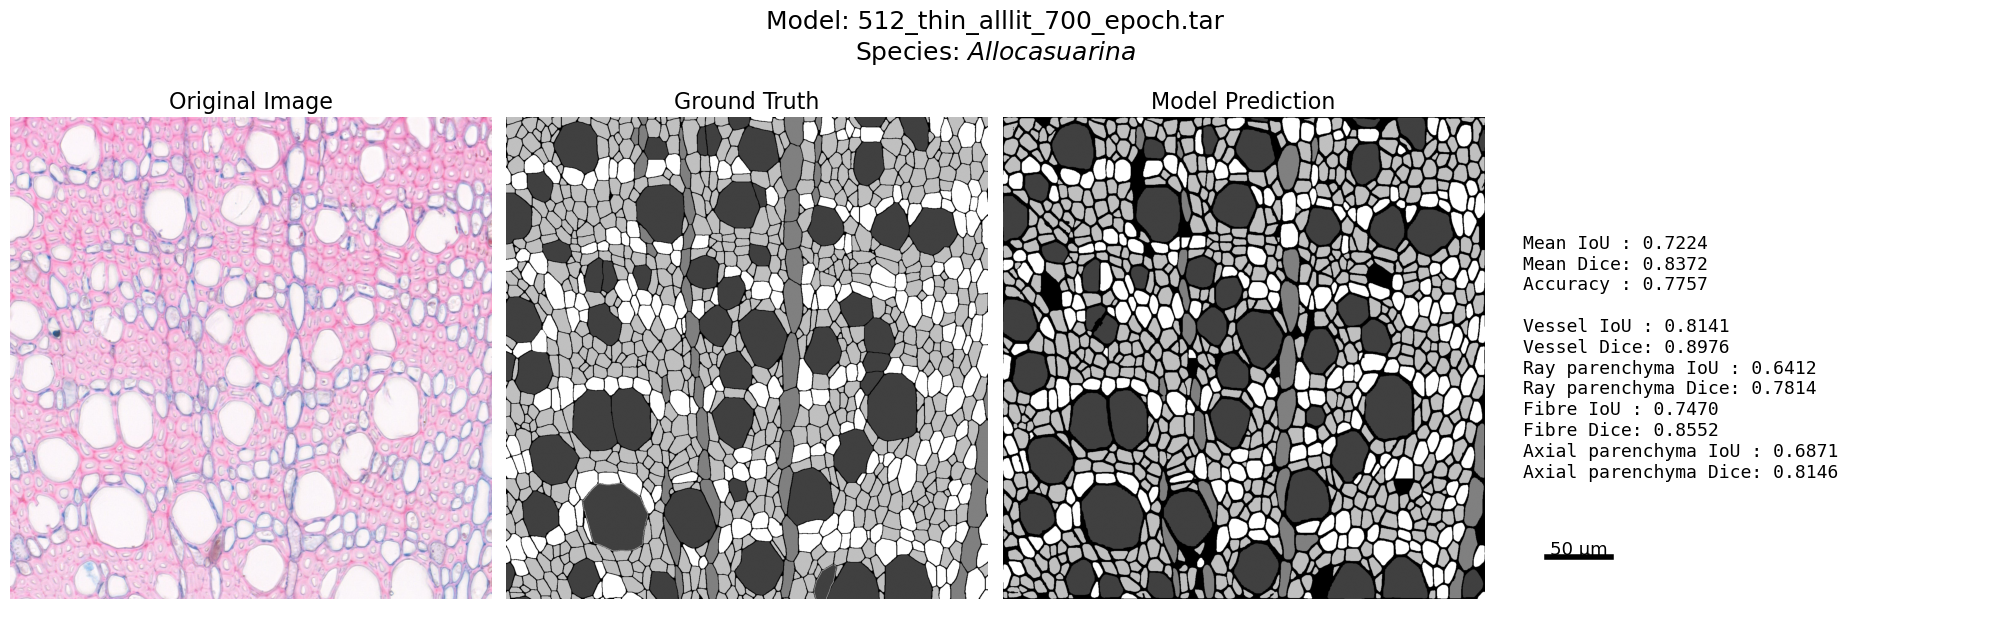

In [26]:
from matplotlib import gridspec


plt.rcParams['pdf.fonttype'] = 42
# ======= ラベル定義 =======
label_mapping = {0: 0, 64: 1, 128: 2, 192: 3, 255: 4}
num_classes = len(label_mapping)
ignore_class = 0  # stuff を無視


cls_display_name = {
    'vessel': 'Vessel',
    'fiber': 'Fibre',
    'parenchyma': 'Axial parenchyma',
    'ray': 'Ray parenchyma'
}

# ======= ヘルパー関数 =======
def normalize_mask(mask):
    return np.vectorize(label_mapping.get)(mask)

def remap_gt_gray(mask, remap_dict):
    remapped = np.copy(mask)
    for src, dst in remap_dict.items():
        remapped[mask == src] = dst
    return remapped

def clear_border_cells_per_class(gt_raw):
    gt_filtered = np.zeros_like(gt_raw)
    for gray in [64, 128, 192, 255]:
        binary = (gt_raw == gray)
        labeled = label(binary)
        #cleared = clear_border(labeled)
        gt_filtered[labeled > 0] = gray
    return gt_filtered

def compute_iou(gt, pred, num_classes, ignore_class=None):
    iou_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        intersection = np.logical_and(gt_cls, pred_cls).sum()
        union = np.logical_or(gt_cls, pred_cls).sum()
        if union == 0:
            continue
        iou_list.append(intersection / union)
    return np.mean(iou_list), iou_list

def compute_dice(gt, pred, num_classes, ignore_class=None):
    dice_list = []
    for cls in range(num_classes):
        if cls == ignore_class:
            continue
        gt_cls = (gt == cls)
        pred_cls = (pred == cls)
        tp = np.logical_and(gt_cls, pred_cls).sum()
        denom = gt_cls.sum() + pred_cls.sum()
        if denom == 0:
            continue
        dice_list.append(2 * tp / denom)
    return np.mean(dice_list), dice_list

def compute_accuracy(gt, pred, ignore_class=None):
    if ignore_class is None:
        return (gt == pred).sum() / gt.size
    mask = gt != ignore_class
    return (gt[mask] == pred[mask]).sum() / mask.sum()

id_to_classname = {v: k for k, v in category_ids.items()}

# ======= ディレクトリ定義 =======
gt_dir = 'dataset/performance_check/mask'
score_dir = os.path.join(sub_dir, 'scores')
vis_dir = os.path.join(sub_dir, 'visual_comparison')
os.makedirs(score_dir, exist_ok=True)
os.makedirs(vis_dir, exist_ok=True)

# ======= 評価結果保存用リスト =======
score_records = []

# ======= メインループ =======
fnam = os.path.splitext(filename)[0]
fnam_short = fnam[:-4]

input_dir = 'dataset/performance_check/image'
img_path = os.path.join(input_dir, filename)
gt_path = os.path.join(gt_dir, fnam_short + "_msk.png")
pred_dir = os.path.join(sub_dir, 'prediction_cleaned')
pred_path = os.path.join(pred_dir, fnam + "_pred_cleaned.png")

# 入力とGTの読み込み
img = np.array(Image.open(img_path).convert("RGB"))
gt_raw = np.array(Image.open(gt_path).convert("L"))
pred_raw = np.array(Image.open(pred_path).convert("L"))

# GT処理（リマップ + 境界除去 + 正規化）
gt_remap_dict = {0: 64, 64: 128, 128: 192, 192: 255, 255: 0}
gt_remapped = remap_gt_gray(gt_raw, gt_remap_dict)
gt_cleared = clear_border_cells_per_class(gt_remapped)
gt_norm = normalize_mask(gt_cleared)

# 推論結果も正規化
pred_norm = normalize_mask(pred_raw)

# スコア計算
mean_iou, per_class_iou = compute_iou(gt_norm, pred_norm, num_classes, ignore_class)
mean_dice, per_class_dice = compute_dice(gt_norm, pred_norm, num_classes, ignore_class)
acc = compute_accuracy(gt_norm, pred_norm, ignore_class)

# ===
# メインループ
fig, axes = plt.subplots(1, 4, figsize=(20, 6))  # ← 4 → 5 に変更



# --- 種名を species_name_dict から取得 ---
sp_key = sp.capitalize()  # 例: "acapod" → "Acapod"
sp_latex = species_name_dict.get(sp_key, sp_key)  # イタリック形式に変換

# --- 図のタイトルに設定 ---
fig.suptitle(f"Model: {MODEL_FILE} Species: {sp_latex}", fontsize=18, y=1.02)



axes[0].imshow(img)
axes[0].set_title('Original Image', fontsize=16)
axes[0].axis('off')

axes[1].imshow(gt_norm, cmap='gray')
axes[1].set_title('Ground Truth', fontsize=16)
axes[1].axis('off')

axes[2].imshow(pred_norm, cmap='gray')
axes[2].set_title('Model Prediction', fontsize=16)
axes[2].axis('off')


# --- スケールバー追加 ---
# ↓↓↓ スケールバーをここ（axes[2]）に追加 ↓↓↓
# axes[3] をスケールバー専用に使う
axes[3].axis('off')

# 画像サイズ（例：1536px）とスケール変換（0.243 µm/pixel）
img_size_px = 1536
micron_per_pixel = 0.243

# 50 µm に相当するピクセル数（＝スケールバーの長さ）
bar_length_px = 50 / micron_per_pixel  # ≈ 205.76 px

# figureのdpiを考慮したキャンバス（任意で調整）
axes[3].set_xlim(0, img_size_px)
axes[3].set_ylim(0, img_size_px)
axes[3].invert_yaxis()  # 上が上になるように（画像と合わせる）

x_start = img_size_px * 0.1
x_end   = x_start + bar_length_px
y_pos   = img_size_px * 0.9

# スケールバー描画
axes[3].plot([x_start, x_end], [y_pos, y_pos], color='black', linewidth=4)
axes[3].text((x_start + x_end) / 2, y_pos - 50, "50 µm",
             ha='center', va='top', fontsize=13, color='black')

# スコア表示
text = f"Mean IoU : {mean_iou:.4f}\nMean Dice: {mean_dice:.4f}\nAccuracy : {acc:.4f}\n"
for cls_id in range(num_classes):
    if cls_id == ignore_class:
        continue
    cls_key = id_to_classname.get(cls_id, f"Class {cls_id}")
    display_name = cls_display_name.get(cls_key, cls_key)
    text += f"\n{display_name} IoU : {per_class_iou[cls_id - 1]:.4f}"
    text += f"\n{display_name} Dice: {per_class_dice[cls_id - 1]:.4f}"

# スコアテキストを軸の左上に表示
axes[3].text(img_size_px * 0.05, img_size_px * 0.5, text, fontsize=13,
             va='center', ha='left', color='black', family='monospace')

fig.suptitle(f"Model: {MODEL_FILE}\nSpecies: {sp_latex}", fontsize=18, y=1.02)#####
plt.tight_layout()
fig.savefig(os.path.join(vis_dir, f"{fnam}_comparison_with_scalebar.pdf"), dpi=300)
plt.show()
plt.close(fig)

# --- CSV用スコア保存 ---
record = {
    "filename": fnam,
    "mean_iou": mean_iou,
    "mean_dice": mean_dice,
    "accuracy": acc,
}

for cls_id in range(num_classes):
    if cls_id == ignore_class:
        continue
    cls_name = id_to_classname.get(cls_id, f"class{cls_id}")
    record[f"{cls_name}_iou"] = per_class_iou[cls_id - 1]
    record[f"{cls_name}_dice"] = per_class_dice[cls_id - 1]
score_records.append(record)

# --- 全スコアをCSV保存 ---
df_scores = pd.DataFrame(score_records)
df_scores.to_csv(os.path.join(score_dir, f"{fnam}_evaluation_scores.csv"), index=False)
